Combine processed NDVI data and fit DLC curves to the data.

In [1]:
import rasterio
from rasterio.merge import merge
import xarray as xr
import glob
import os
import matplotlib.pyplot as plt

from datetime import datetime, timedelta
import pandas as pd
from scipy.optimize import curve_fit
import numpy as np

## folder where exported tiles are located
folder_path = "H:/My Drive/NDVI_Exports"

## get a list of all the GeoTIFF files in the folder
tile_files = glob.glob(os.path.join(folder_path, "*.tif"))

## read and merge tiles
src_files = [rasterio.open(tile) for tile in tile_files]
mosaic_array, mosaic_transform = merge(src_files) ## the mosaic_array is the actual raster, the mosaic_transform is what allows it to map the coordinates to the correct place when it's added together

## get metadata from the first tile to use in the merged output
meta = src_files[0].meta.copy()
meta.update({
    "driver": "GTiff",
    "height": mosaic_array.shape[1],
    "width": mosaic_array.shape[2],
    "transform": mosaic_transform
})

## close all individual tile files
for src in src_files:
    src.close()


In [2]:
# Convert the merged array to an xarray DataArray
# Assume each layer corresponds to one of the 8-day NDVI periods
mosaic_da = xr.DataArray(
    mosaic_array, 
    dims=("band", "y", "x"),
    name="NDVI",
    attrs=meta
)

# Wrap the DataArray in an xarray Dataset for easier handling
mosaic_ds = mosaic_da.to_dataset(name="NDVI")
mosaic_ds = mosaic_ds.sortby("y", ascending=False)

# Inspect the structure (dimensions, attributes, etc.)
print(mosaic_ds)
print("Dimensions:", mosaic_ds.dims)
print("Variables:", mosaic_ds.data_vars)
print("Attributes:", mosaic_ds.attrs)

# Access the names of each layer (corresponds to "band" dimension)
print("Number of Bands (days):", mosaic_ds.dims['band'])


<xarray.Dataset> Size: 33MB
Dimensions:  (band: 46, y: 376, x: 479)
Dimensions without coordinates: band, y, x
Data variables:
    NDVI     (band, y, x) float32 33MB 0.021 0.0147 0.01492 ... 0.09778 0.09778
Dimensions: FrozenMappingWarningOnValuesAccess({'band': 46, 'y': 376, 'x': 479})
Variables: Data variables:
    NDVI     (band, y, x) float32 33MB 0.021 0.0147 0.01492 ... 0.09778 0.09778
Attributes: {}
Number of Bands (days): 46


C:\Users\tlasharr\AppData\Local\Temp\ipykernel_14996\4052775104.py:21: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("Number of Bands (days):", mosaic_ds.dims['band'])


In [3]:
##  convert to an np array
stacked_data = np.stack([mosaic_ds['NDVI'].isel(band=i).values for i in range(mosaic_ds.dims['band'])], axis=0)
print(stacked_data.shape)  # number_of_bands, height, width

## calculate min and max along the stack (axis 0)
min_val = np.nanmin(stacked_data, axis=0)
max_975_quantile = np.nanquantile(stacked_data, 0.975, axis=0)

## avoid division by zero by adding a small epsilon value
epsilon = 1e-10
denominator = max_975_quantile - min_val + epsilon

## get the scaled data of the raster stack
scaled_data = (stacked_data - min_val) / denominator

## check the scaled data values to confirm
print("Min Values:", min_val)
print("Max 97.5th Percentile Values:", max_975_quantile)
print("Scaled Data:", scaled_data)

## optional: check the shape of the scaled_data to confirm
print("Scaled Data Shape:", scaled_data.shape) # bands, rows, columns


(46, 376, 479)


C:\Users\tlasharr\AppData\Local\Temp\ipykernel_14996\2396407354.py:2: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  stacked_data = np.stack([mosaic_ds['NDVI'].isel(band=i).values for i in range(mosaic_ds.dims['band'])], axis=0)
C:\Users\tlasharr\AppData\Local\Temp\ipykernel_14996\2396407354.py:6: RuntimeWarning: All-NaN slice encountered
  min_val = np.nanmin(stacked_data, axis=0)
c:\Users\tlasharr\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Min Values: [[0.02099931 0.01470068 0.01491869 ... 0.00741535 0.00489369 0.00316904]
 [0.02126689 0.0214584  0.0214584  ... 0.00664282 0.00391795 0.00391795]
 [0.02740678 0.01847864 0.0265902  ... 0.01074437 0.01116514 0.01264607]
 ...
 [       nan        nan        nan ... 0.05446064 0.06760359 0.03777641]
 [       nan 0.4094732  0.4094732  ... 0.10343533 0.10343533 0.0264148 ]
 [       nan 0.5620898  0.3242168  ... 0.04670355 0.09777784 0.09777784]]
Max 97.5th Percentile Values: [[0.62157196 0.47474286 0.47396597 ... 0.14905934 0.1440691  0.16067638]
 [0.47828433 0.48640364 0.48640364 ... 0.15169455 0.19879389 0.19879389]
 [0.4513349  0.43615174 0.44474462 ... 0.2412696  0.25776064 0.23568264]
 ...
 [       nan        nan        nan ... 0.1838565  0.18763448 0.30350193]
 [       nan 0.6463654  0.6463654  ... 0.22022156 0.22022156 0.27038628]
 [       nan 0.620603   0.6589506  ... 0.31732717 0.24836749 0.24836749]]
Scaled Data: [[[0.         0.         0.         ... 0.         0.    

In [4]:
## define the DLC model

def dlc_model(time, xmidS, scalS, xmidA, scalA):
    return (1 / (1 + np.exp((xmidS - time) / scalS))) - (1 / (1 + np.exp((xmidA - time) / scalA)))


In [ ]:
years = [2017]

## get the dates
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year

dates = pd.to_datetime(dates)

## intial parameters to try for the DLC
dlc_bounds = ([30, 1, 167, 1], [228, 30, 288, 35])

## run the function for each pixel seperately
def fit_dlc_per_pixel(ndvi_data, time, dlc_bounds):
    if np.isnan(ndvi_data).any() or len(ndvi_data[~np.isnan(ndvi_data)]) < 4:
        return [np.nan] * 8  # return NaNs if insufficient data

    try:
        ## initial parameter guesses
        initial_guess = [130, 10, 230, 17]
        
        ## perform the curve fitting
        popt, pcov = curve_fit(dlc_model, time, ndvi_data, p0=initial_guess, bounds=dlc_bounds)
        
        ## extract standard errors from the covariance matrix
        perr = np.sqrt(np.diag(pcov))
        
        ## return parameters and standard errors
        return list(popt) + list(perr)
    
    except Exception as e:
        print(f"Error fitting pixel: {e}")
        return [np.nan] * 8

## process the data for each year seperately
def fit_dlc_for_year(ndvi_stack, dates, years, dlc_bounds):
    results = []
    
    for year in years:
        # Subset NDVI data to current year
        year_indices = [i for i, date in enumerate(dates) if date.year == year]
        ndvi_year = ndvi_stack[year_indices]
        time = np.array([date.timetuple().tm_yday for i, date in enumerate(dates) if date.year == year])
        
        # Initialize result array for current year
        dlc_params = np.full((*ndvi_year.shape[1:], 8), np.nan)
        
        # Loop over each pixel
        for row in range(ndvi_year.shape[1]):
            for col in range(ndvi_year.shape[2]):
                ndvi_pixel = ndvi_year[:, row, col]
                dlc_params[row, col, :] = fit_dlc_per_pixel(ndvi_pixel, time, dlc_bounds)
                
        results.append(dlc_params)
    
    return np.stack(results, axis=0)  # Shape: (years, rows, cols, params)


## fit the DLC model for each year
dlc_results = fit_dlc_for_year(stacked_data, dates, years, dlc_bounds)

print("DLC Parameters Shape:", dlc_results.shape) ## years, 

Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.


In [ ]:

# Function to calculate fitted NDVI values for each pixel based on the DLC parameters
def calculate_fitted_vals(dlc_params, dates, values="daily"):
    time = np.arange(1, 366) if values == "daily" else np.arange(1, 366, 7)
    fitted_vals = np.full((dlc_params.shape[0], dlc_params.shape[1], len(time)), np.nan)
    
    for row in range(dlc_params.shape[0]):
        for col in range(dlc_params.shape[1]):
            params = dlc_params[row, col, :4]
            if np.isnan(params).any():
                continue  # Skip pixels with NaN parameters
            fitted_vals[row, col, :] = dlc_model(time, *params)
    
    return fitted_vals

# Function to calculate Instantaneous Rate of Green-up (IRG)
def calculate_irg(fitted_vals, sclIRG=True):
    # Calculate the difference along the time dimension (axis=2)
    irg = np.diff(fitted_vals, axis=2)
    
    # Pad the last day with NaN to keep the dimensions consistent
    irg = np.concatenate((irg, np.full(irg.shape[:-1] + (1,), np.nan)), axis=2)
    
    # Set negative IRG values to 0
    irg[irg < 0] = 0
    
    # Scale IRG values between 0 and 1 if required
    if sclIRG:
        irg_min = np.nanmin(irg)
        irg_max = np.nanmax(irg)
        if irg_max > irg_min:  # Prevent division by zero
            irg = (irg - irg_min) / (irg_max - irg_min)
    
    return irg


# Function to calculate max values and peak dates, with handling for all-NaN slices
def calculate_max_and_dates(values_array, time_points, func="max"):
    # Initialize arrays to hold results, filled with NaNs initially
    max_vals = np.full(values_array.shape[:2], np.nan)
    max_dates = np.full(values_array.shape[:2], np.nan)

    for row in range(values_array.shape[0]):
        for col in range(values_array.shape[1]):
            pixel_values = values_array[row, col, :]
            if np.isnan(pixel_values).all():
                continue  # Skip if all values are NaN for this pixel
            
            # Calculate max value and corresponding date
            max_vals[row, col] = np.nanmax(pixel_values)
            max_dates[row, col] = time_points[np.nanargmax(pixel_values)]
    
    return max_vals, max_dates

# Prepare time indices for date calculations
years = [2017]
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year
dates = pd.to_datetime(dates)

# Calculate fitted values and IRG for year 2017
time_points = np.arange(1, 366)  # Day of year for daily calculations
fitted_vals = calculate_fitted_vals(dlc_results[0, :, :, :], dates)  # for year 1, e.g., 2017
irg_vals = calculate_irg(fitted_vals)

# Calculate max values and dates
max_ndvi, max_ndvi_date = calculate_max_and_dates(fitted_vals, time_points, func="max")
max_irg, max_irg_date = calculate_max_and_dates(irg_vals, time_points, func="max")

print("Max NDVI Value:", max_ndvi)
print("Max NDVI date:", max_ndvi_date)

print("Max IRG Value:", max_irg)
print("Max IRG Date:", max_irg_date)



Max NDVI Value: [[0.65426522 0.52527608 0.50325874 ... 0.1922054  0.18664537 0.16841942]
 [0.51017466 0.53253843 0.53253843 ... 0.20152204 0.23273158 0.23273158]
 [0.50094271 0.48554563 0.47192442 ... 0.29936864 0.30749188 0.28948911]
 ...
 [       nan        nan        nan ... 0.23314292 0.2305162  0.36726385]
 [       nan 0.71461507 0.71461507 ... 0.27144436 0.27144436 0.33834959]
 [       nan 0.9483506  0.66144791 ... 0.36910343 0.28536788 0.28536788]]
Max NDVI date: [[198. 191. 188. ... 210. 197. 230.]
 [193. 191. 191. ... 185. 229. 229.]
 [189. 191. 189. ... 160. 159. 159.]
 ...
 [ nan  nan  nan ... 161. 162. 166.]
 [ nan 169. 169. ... 157. 157. 163.]
 [ nan 164. 197. ... 153. 155. 155.]]
Max IRG Value: [[0.03175671 0.02549338 0.02465022 ... 0.01068533 0.01057806 0.00930107]
 [0.02491701 0.02576606 0.02576606 ... 0.01134274 0.01262992 0.01262992]
 [0.02455813 0.02395426 0.02340869 ... 0.01589833 0.01627109 0.01544274]
 ...
 [       nan        nan        nan ... 0.0128214  0.012697

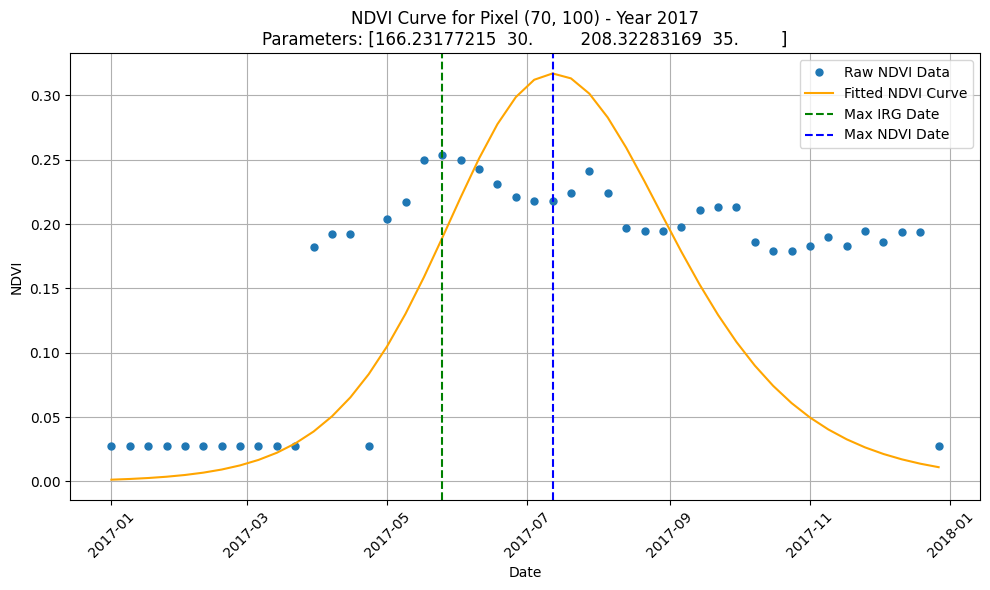

In [29]:
# Function to calculate fitted NDVI values for specific dates (8-day intervals) based on DLC parameters
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot fitted and raw NDVI data with lines for max IRG and NDVI dates
def plot_ndvi_pixel(dlc_results, stacked_data, dates, row, col):
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing when there's only one subplot
    
    for i, year in enumerate(years):
        ## Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        ## Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        ## Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        ## Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = stacked_data[year_indices, row, col]
        
        ## Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Raw NDVI Data", linestyle='None', markersize=5)
        
        ## Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Pixel ({row}, {col}) - Year {year}\nParameters: {params}")
            
            ## Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='--', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='--', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Pixel ({row}, {col}) - Year {year} (No Fit)")
        
        ## Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

## Specify row and column indices for the pixel you want to analyze
row_index = 70 
col_index = 100  

## Plot the raw and fitted NDVI data for the specified pixel across years
plot_ndvi_pixel(dlc_results, stacked_data, dates, row_index, col_index)


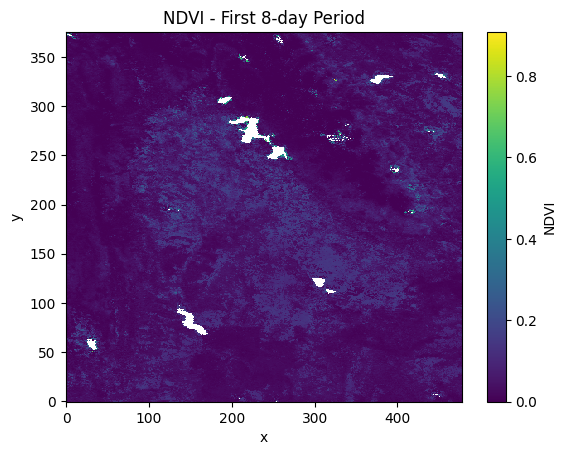

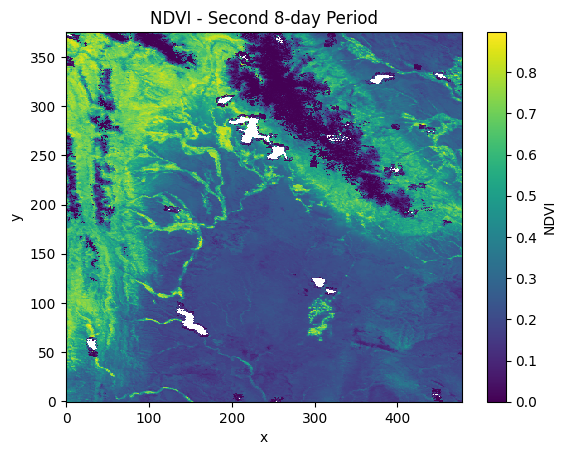

In [13]:

# Plot the first 8-day period layer (band index 0)
mosaic_ds.NDVI.isel(band=0).plot()
plt.title("NDVI - First 8-day Period")
plt.show()

# Plot the second 8-day period layer (band index 1)
mosaic_ds.NDVI.isel(band=22).plot()
plt.title("NDVI - Second 8-day Period")
plt.show()
